# 02 · Correlation Analysis and Time Series
**Module 3 (CO3)** — Bike Sharing Demand EDA

| Syllabus topic | Section |
|---|---|
| Univariate, bivariate and multivariate analysis | §1–§3 |
| Fundamentals and characteristics of Time Series Analysis | §4 |
| Time-based indexing | §5 |
| Visualizing, grouping and resampling time series | §6–§8 |

Input: `data/processed/hour_clean.csv` produced by notebook 01.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf

from utils import set_style, save_fig, load_clean_hourly, PALETTE, SEASONS, WEATHER, WEEKDAYS, DIV_CMAP, SEQ_CMAP

set_style()
hourly = load_clean_hourly()
print(hourly.shape)
hourly.head(3)

(17379, 19)


,date,year,month,hour,season,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,cnt,temp_band,demand_level,time_of_day
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,2011-01-01,2011,1,0,Spring,0,Sat,0,Clear,9.84,14.40,81.0,6.0,3,13,16,Cold,Low,Night
2011-01-01 01:00:00,2011-01-01,2011,1,1,Spring,0,Sat,0,Clear,9.02,13.64,80.0,6.0,8,32,40,Cold,Low,Night
2011-01-01 02:00:00,2011-01-01,2011,1,2,Spring,0,Sat,0,Clear,9.02,13.64,80.0,6.0,5,27,32,Cold,Low,Night


## 1. Univariate analysis
One variable at a time: its centre, spread, shape and outliers.

In [2]:
hourly["cnt"].describe().round(1)

count    17379.0
mean       189.5
std        181.4
min          1.0
25%         40.0
50%        142.0
75%        281.0
max        977.0
Name: cnt, dtype: float64

Skewness: 1.277 | Kurtosis: 1.417


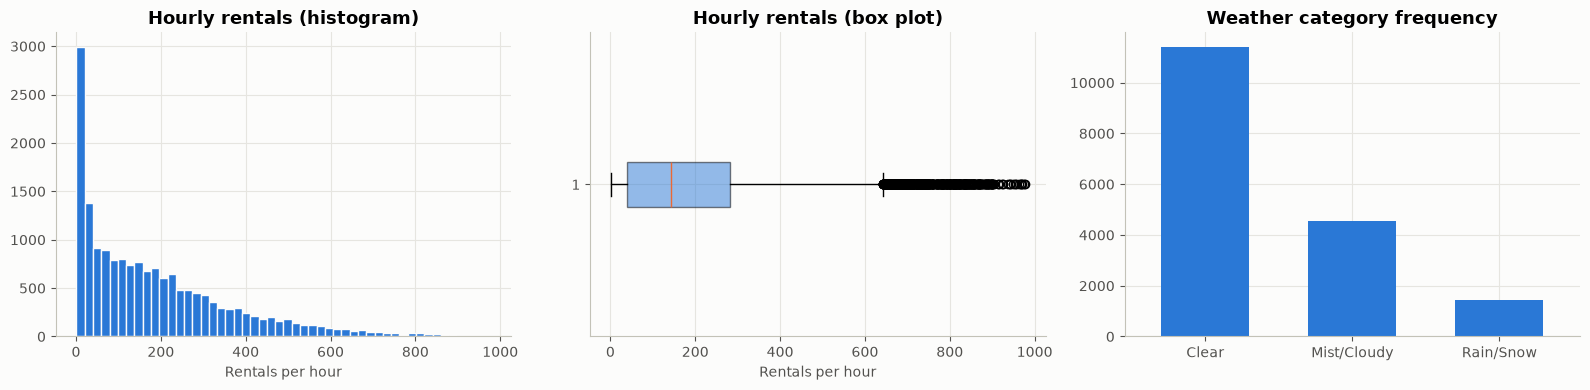

In [3]:
print("Skewness:", round(hourly["cnt"].skew(), 3), "| Kurtosis:", round(hourly["cnt"].kurt(), 3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(hourly["cnt"], bins=50, color=PALETTE[0], edgecolor="#fcfcfb")
axes[0].set_title("Hourly rentals (histogram)")
axes[0].set_xlabel("Rentals per hour")
axes[1].boxplot(hourly["cnt"], orientation="horizontal", patch_artist=True,
                boxprops=dict(facecolor=PALETTE[0], alpha=0.5), medianprops=dict(color=PALETTE[1]))
axes[1].set_title("Hourly rentals (box plot)")
axes[1].set_xlabel("Rentals per hour")
hourly["weather"].value_counts().reindex(WEATHER).plot.bar(ax=axes[2], color=PALETTE[0], width=0.6)
axes[2].set_title("Weather category frequency")
axes[2].tick_params(axis="x", rotation=0)
axes[2].set_xlabel("")
fig.tight_layout()
save_fig(fig, "02_univariate")
plt.show()

**Observation:** hourly rentals are strongly **right-skewed** (mean > median, long tail up to ~980). Many "outliers" in the box plot are simply normal peak-hour demand. Most hours (~66%) have clear weather.

## 2. Bivariate analysis
Relationship between two variables: numeric–numeric (scatter, correlation) and categorical–numeric (box plots, group means).

In [4]:
pairs = [("temp", "cnt"), ("atemp", "cnt"), ("humidity", "cnt"), ("windspeed", "cnt"), ("temp", "atemp")]
rows = []
for x, y in pairs:
    r, p = stats.pearsonr(hourly[x], hourly[y])
    rho, _ = stats.spearmanr(hourly[x], hourly[y])
    rows.append({"pair": f"{x} vs {y}", "Pearson r": r, "Spearman ρ": rho, "p-value": p})
pd.DataFrame(rows).round(4)

,pair,Pearson r,Spearman ρ,p-value
0,temp vs cnt,0.4046,0.4231,0.0
1,atemp vs cnt,0.4009,0.4233,0.0
2,humidity vs cnt,-0.3227,-0.3594,0.0
3,windspeed vs cnt,0.0955,0.1408,0.0
4,temp vs atemp,0.9875,0.9895,0.0


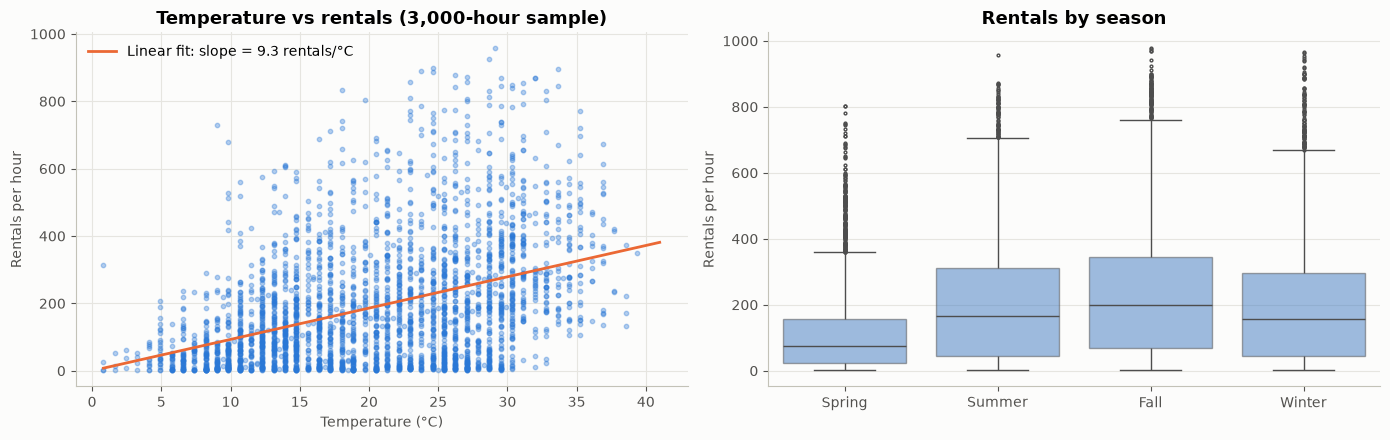

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sample = hourly.sample(3000, random_state=0)
axes[0].scatter(sample["temp"], sample["cnt"], s=10, alpha=0.35, color=PALETTE[0])
m, b = np.polyfit(hourly["temp"], hourly["cnt"], 1)
xs = np.linspace(hourly["temp"].min(), hourly["temp"].max(), 50)
axes[0].plot(xs, m * xs + b, color=PALETTE[1], label=f"Linear fit: slope = {m:.1f} rentals/°C")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Rentals per hour")
axes[0].set_title("Temperature vs rentals (3,000-hour sample)")
axes[0].legend()

sns.boxplot(data=hourly, x="season", y="cnt", order=SEASONS, ax=axes[1], color=PALETTE[0],
            boxprops=dict(alpha=0.5), fliersize=2)
axes[1].set_title("Rentals by season")
axes[1].set_xlabel("")
axes[1].set_ylabel("Rentals per hour")
fig.tight_layout()
save_fig(fig, "02_bivariate")
plt.show()

In [6]:
# Is the difference between seasons significant? One-way ANOVA
groups = [hourly.loc[hourly.season == s, "cnt"] for s in SEASONS]
f, p = stats.f_oneway(*groups)
print(f"ANOVA across seasons: F = {f:.1f}, p = {p:.2e}")
hourly.groupby("season")["cnt"].mean().reindex(SEASONS).round(1)

ANOVA across seasons: F = 409.2, p = 7.40e-257


season
Spring    111.1
Summer    208.3
Fall      236.0
Winter    198.9
Name: cnt, dtype: float64

**Observations**
- Temperature has the strongest positive link with rentals (r ≈ 0.40); humidity is negative (r ≈ −0.32).
- `temp` and `atemp` are almost perfectly correlated (r ≈ 0.99) — they carry the same information, so only one should be used in a regression model (multicollinearity).
- Spring has clearly the lowest demand; the ANOVA confirms season matters (p ≪ 0.05). Note: in this dataset "Spring" is roughly Jan–Mar, the coldest months.

## 3. Multivariate analysis
Three or more variables together: a correlation matrix, a pair plot, and a two-factor heatmap.

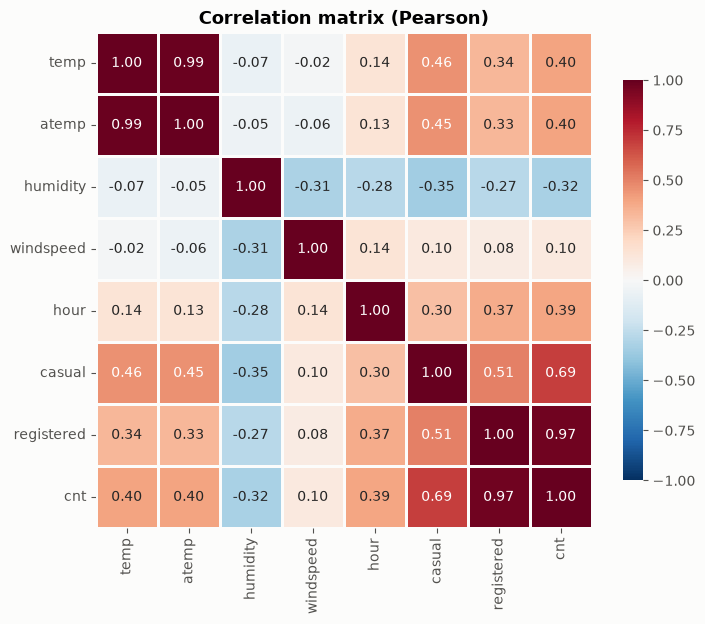

In [7]:
num_cols = ["temp", "atemp", "humidity", "windspeed", "hour", "casual", "registered", "cnt"]
corr = hourly[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIV_CMAP, vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="#fcfcfb", ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation matrix (Pearson)")
save_fig(fig, "02_correlation_matrix")
plt.show()

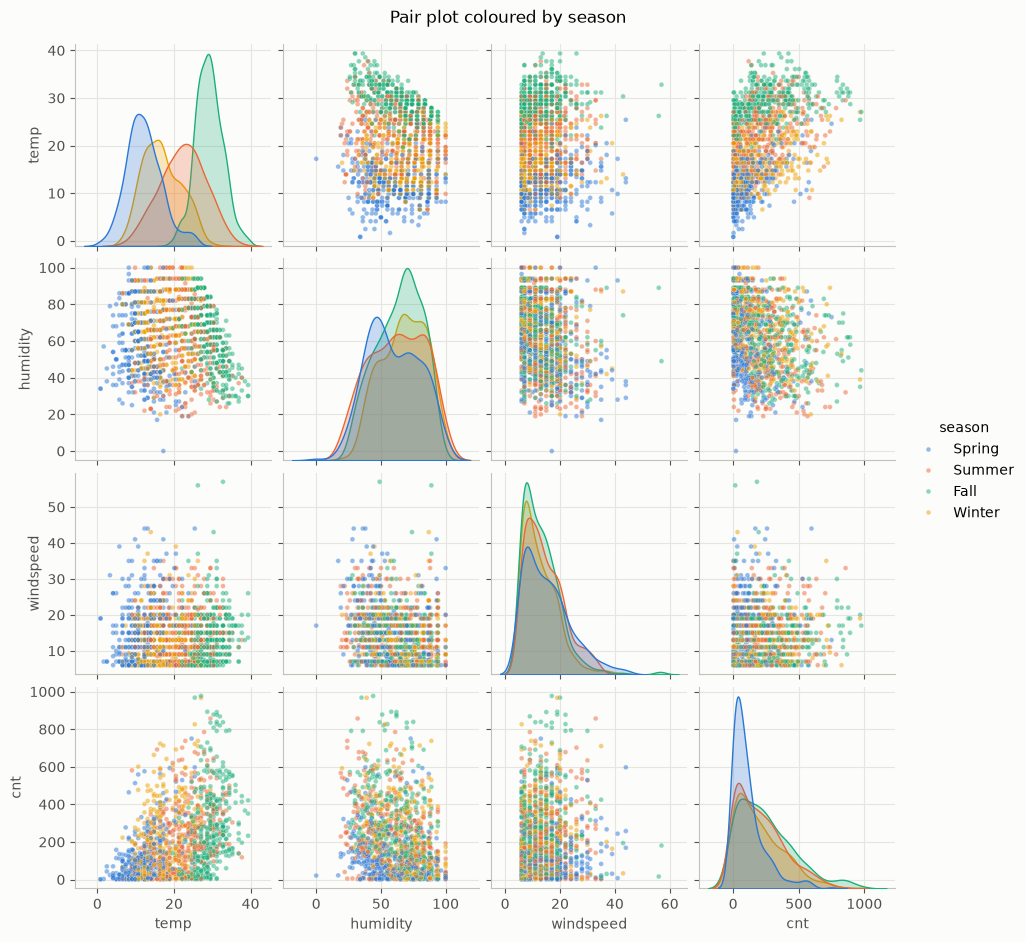

In [8]:
g = sns.pairplot(hourly.sample(1500, random_state=1), vars=["temp", "humidity", "windspeed", "cnt"],
                 hue="season", hue_order=SEASONS, palette=PALETTE[:4],
                 plot_kws=dict(s=12, alpha=0.5), diag_kind="kde", height=2.3)
g.figure.suptitle("Pair plot coloured by season", y=1.02)
save_fig(g.figure, "02_pairplot")
plt.show()

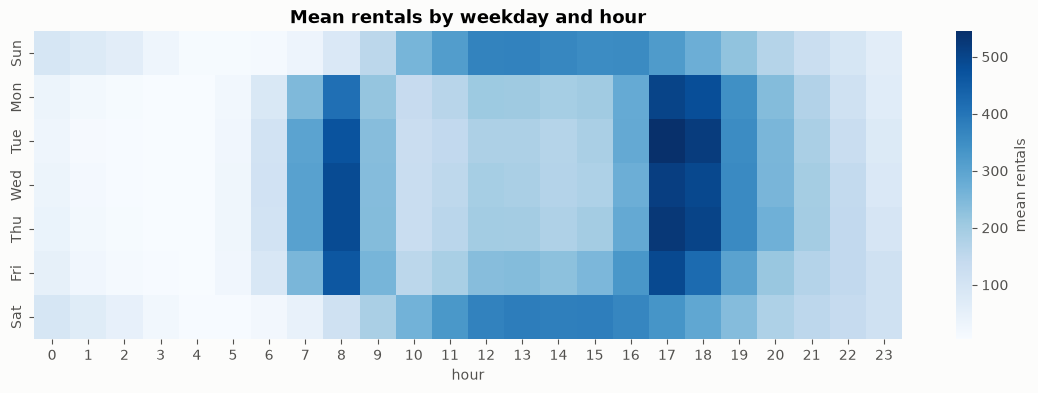

In [9]:
# Three variables at once: hour × weekday -> mean rentals
pivot = hourly.pivot_table(index="weekday", columns="hour", values="cnt", aggfunc="mean").reindex(WEEKDAYS)
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(pivot, cmap=SEQ_CMAP, ax=ax, cbar_kws={"label": "mean rentals"})
ax.set_title("Mean rentals by weekday and hour")
ax.set_ylabel("")
save_fig(fig, "02_heatmap_weekday_hour")
plt.show()

**Observations**
- `registered` users drive total demand (r ≈ 0.97 with `cnt`), while `casual` users react more strongly to temperature.
- The heatmap shows two very different daily patterns: **weekdays** have sharp peaks at 8 AM and 5–6 PM (commuting), while **weekends** have one broad midday hump (leisure).

## 4. Time Series Analysis — fundamentals
A **time series** is a sequence of observations indexed by time at regular intervals. Its main **characteristics** are:

| Component | Meaning | In bike data |
|---|---|---|
| **Trend** | long-term increase / decrease | 2012 demand is much higher than 2011 (system growth) |
| **Seasonality** | fixed-period repeating pattern | daily (24 h), weekly (7 d) and yearly cycles |
| **Cyclic** | rises and falls without a fixed period | economy-driven, not visible over 2 years |
| **Irregular / noise** | random variation | storms, holidays, sensor issues |

Other key ideas: **stationarity** (constant mean/variance over time — needed by many forecasting models), **autocorrelation** (correlation of a series with its own past values), and **additive vs multiplicative** decomposition.

## 5. Time-based indexing
With a `DatetimeIndex`, pandas allows slicing by date strings, partial dates and time-of-day.

In [10]:
print(type(hourly.index), hourly.index.min(), "→", hourly.index.max())

<class 'pandas.DatetimeIndex'> 2011-01-01 00:00:00 → 2012-12-31 23:00:00


In [11]:
# Single day by partial string
hourly.loc["2012-07-04", ["hour", "temp", "cnt"]].head()

,hour,temp,cnt
datetime,,,
2012-07-04 00:00:00,0,27.88,159
2012-07-04 01:00:00,1,27.88,123
2012-07-04 02:00:00,2,27.06,93
2012-07-04 03:00:00,3,27.88,32
2012-07-04 04:00:00,4,27.88,16


In [12]:
# Whole month, and a date range
print("Rows in June 2012:", len(hourly.loc["2012-06"]))
print("Rentals 1–7 Jan 2012:", hourly.loc["2012-01-01":"2012-01-07", "cnt"].sum())

Rows in June 2012: 720
Rentals 1–7 Jan 2012: 20740


In [13]:
# Time-of-day selection across all dates, and index attributes
rush = hourly.between_time("07:00", "09:00")
print("Mean rentals 7–9 AM:", round(rush["cnt"].mean(), 1), "vs overall", round(hourly["cnt"].mean(), 1))
pd.DataFrame({"quarter": hourly.index.quarter, "dayofyear": hourly.index.day_of_year,
              "is_month_end": hourly.index.is_month_end}, index=hourly.index).iloc[::4000]

Mean rentals 7–9 AM: 263.5 vs overall 189.5


,quarter,dayofyear,is_month_end
datetime,,,
2011-01-01 00:00:00,1,1,False
2011-06-20 14:00:00,2,171,False
2011-12-05 00:00:00,4,339,False
2012-05-20 05:00:00,2,141,False
2012-11-04 09:00:00,4,309,False


## 6. Visualizing time series

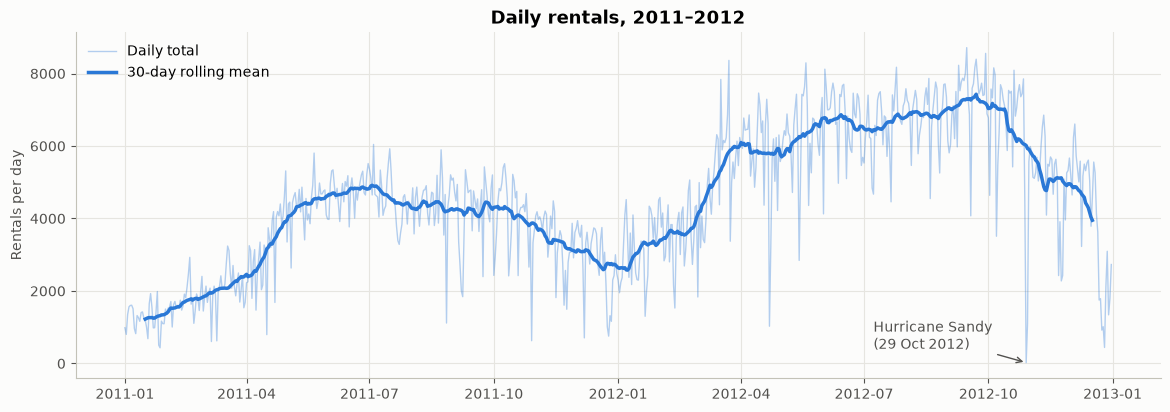

In [14]:
daily_cnt = hourly["cnt"].resample("D").sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(daily_cnt, color=PALETTE[0], alpha=0.35, linewidth=1, label="Daily total")
ax.plot(daily_cnt.rolling(30, center=True).mean(), color=PALETTE[0], linewidth=2.5, label="30-day rolling mean")
low = daily_cnt.nsmallest(1)
ax.annotate("Hurricane Sandy\n(29 Oct 2012)", xy=(low.index[0], low.iloc[0]), xytext=(-110, 10),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#52514e"), color="#52514e")
ax.set_ylabel("Rentals per day")
ax.set_title("Daily rentals, 2011–2012")
ax.legend(loc="upper left")
save_fig(fig, "02_daily_series")
plt.show()

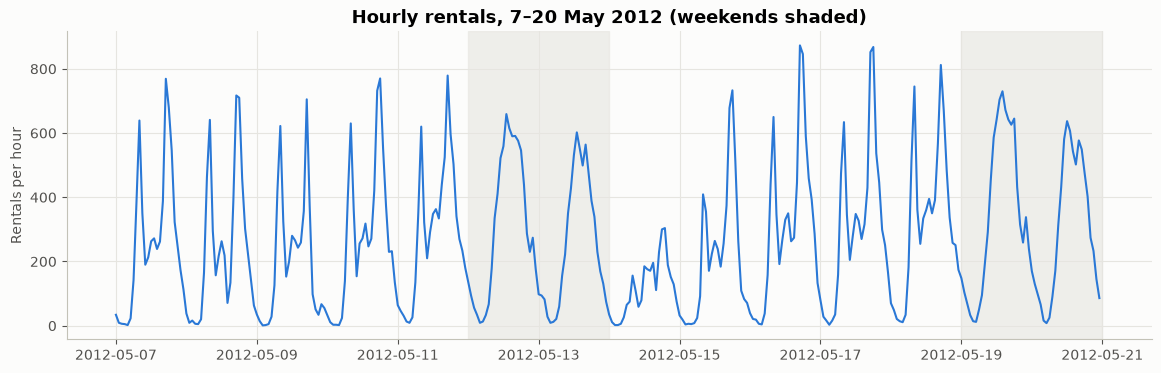

In [15]:
# Zoom: two weeks of hourly data shows daily seasonality and the weekend effect
fig, ax = plt.subplots(figsize=(14, 4))
two_weeks = hourly.loc["2012-05-07":"2012-05-20", "cnt"]
ax.plot(two_weeks, color=PALETTE[0], linewidth=1.5)
for d in pd.date_range("2012-05-12", "2012-05-20", freq="7D"):
    ax.axvspan(d, d + pd.Timedelta(days=2), color="#e6e5e0", alpha=0.6)
ax.set_title("Hourly rentals, 7–20 May 2012 (weekends shaded)")
ax.set_ylabel("Rentals per hour")
save_fig(fig, "02_hourly_zoom")
plt.show()

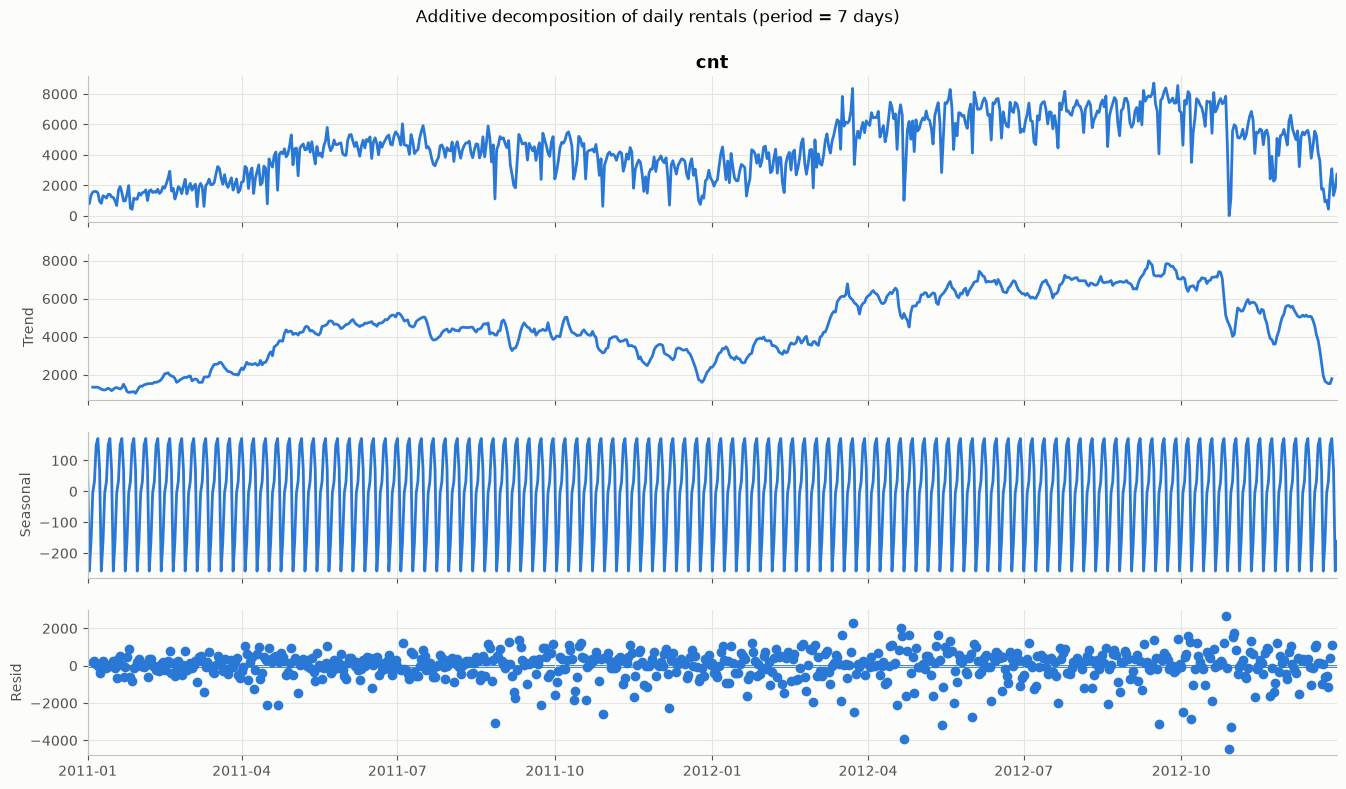

In [16]:
# Classical decomposition of the daily series (weekly period)
decomp = seasonal_decompose(daily_cnt.interpolate(), model="additive", period=7)
fig = decomp.plot()
fig.set_size_inches(14, 8)
for ax in fig.axes:
    for line in ax.get_lines():
        line.set_color(PALETTE[0])
fig.suptitle("Additive decomposition of daily rentals (period = 7 days)", y=1.01)
save_fig(fig, "02_decomposition")
plt.show()

ADF on daily counts: statistic = -1.877, p-value = 0.343
ADF on differenced  : statistic = -11.779, p-value = 1.05e-21


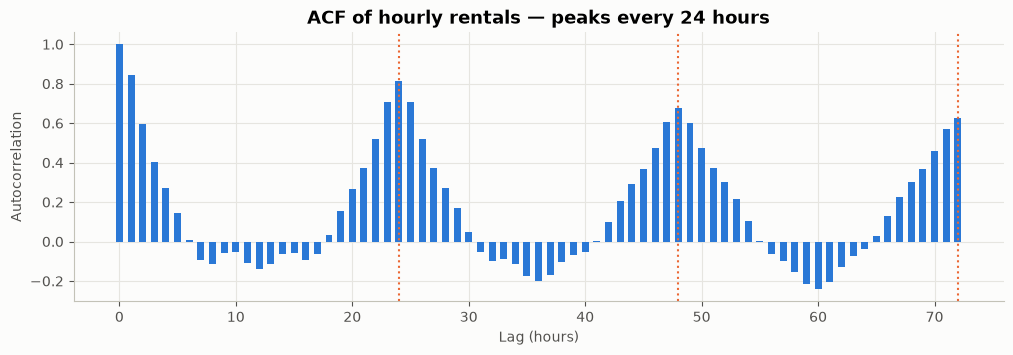

In [17]:
# Stationarity (ADF test) and autocorrelation
adf_stat, adf_p, *_ = adfuller(daily_cnt, result_object=False)
print(f"ADF on daily counts: statistic = {adf_stat:.3f}, p-value = {adf_p:.3f}")
adf_stat2, adf_p2, *_ = adfuller(daily_cnt.diff().dropna(), result_object=False)
print(f"ADF on differenced  : statistic = {adf_stat2:.3f}, p-value = {adf_p2:.2e}")

lags = acf(hourly["cnt"], nlags=72)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(lags)), lags, color=PALETTE[0], width=0.6)
for lag in (24, 48, 72):
    ax.axvline(lag, color=PALETTE[1], linestyle=":", linewidth=1.5)
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.set_title("ACF of hourly rentals — peaks every 24 hours")
save_fig(fig, "02_acf")
plt.show()

**Observations**
- The raw daily series is **not stationary** (ADF p > 0.05) because of trend and yearly seasonality; after first differencing it becomes stationary (p ≪ 0.05).
- The ACF has peaks at 24, 48 and 72 hours → strong **daily seasonality**.

## 7. Grouping time series data

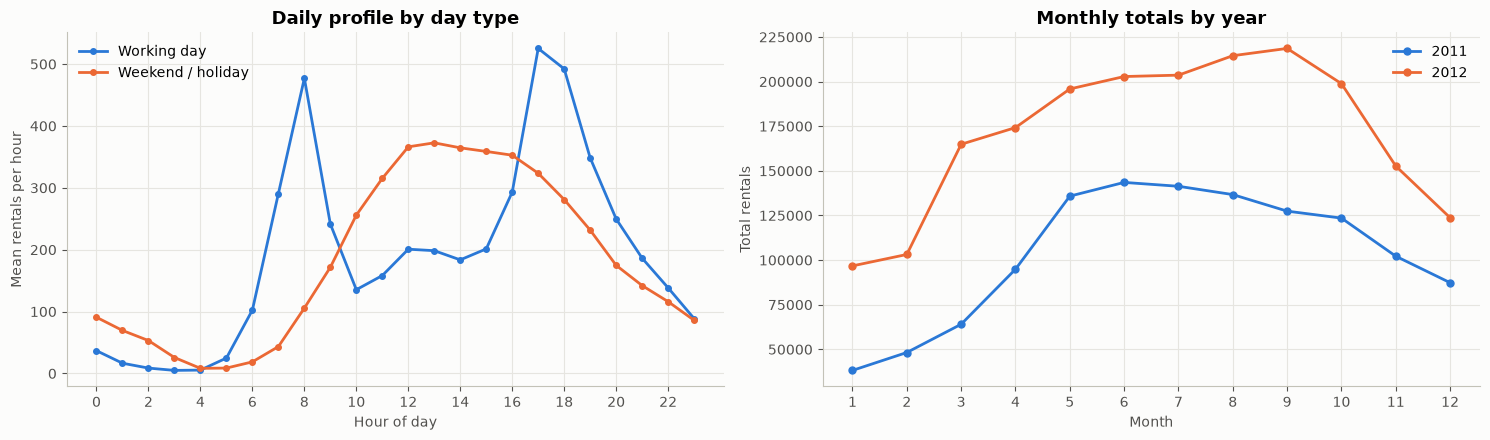

datetime
2011    1243103
2012    2049576
Name: cnt, dtype: int64 
Year-on-year growth: 64.9%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Mean hourly profile: working day vs non-working day
prof = hourly.groupby(["workingday", "hour"])["cnt"].mean().unstack(0)
axes[0].plot(prof.index, prof[1], color=PALETTE[0], marker="o", markersize=4, label="Working day")
axes[0].plot(prof.index, prof[0], color=PALETTE[1], marker="o", markersize=4, label="Weekend / holiday")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean rentals per hour")
axes[0].set_title("Daily profile by day type")
axes[0].legend()

# Monthly totals by year
monthly = hourly.groupby([hourly.index.year, hourly.index.month])["cnt"].sum().unstack(0)
axes[1].plot(monthly.index, monthly[2011], color=PALETTE[0], marker="o", markersize=5, label="2011")
axes[1].plot(monthly.index, monthly[2012], color=PALETTE[1], marker="o", markersize=5, label="2012")
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total rentals")
axes[1].set_title("Monthly totals by year")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "02_grouping")
plt.show()

growth = hourly.groupby(hourly.index.year)["cnt"].sum()
print(growth, f"\nYear-on-year growth: {(growth[2012] / growth[2011] - 1) * 100:.1f}%")

## 8. Resampling time series data
- **Downsampling** (higher → lower frequency) aggregates: hourly → daily / weekly / monthly.
- **Upsampling** (lower → higher frequency) creates new time points that must be filled (ffill / interpolate).

In [19]:
resampled = pd.DataFrame({
    "Daily": hourly["cnt"].resample("D").sum().describe(),
    "Weekly": hourly["cnt"].resample("W").sum().describe(),
    "Monthly": hourly["cnt"].resample("ME").sum().describe(),
}).round(0)
resampled

,Daily,Weekly,Monthly
count,731.0,106.0,24.0
mean,4504.0,31063.0,137195.0
std,1937.0,12800.0,52267.0
min,22.0,1786.0,38189.0
25%,3152.0,23055.0,100811.0
50%,4548.0,30528.0,136256.0
75%,5956.0,42305.0,179634.0
max,8714.0,55022.0,218573.0


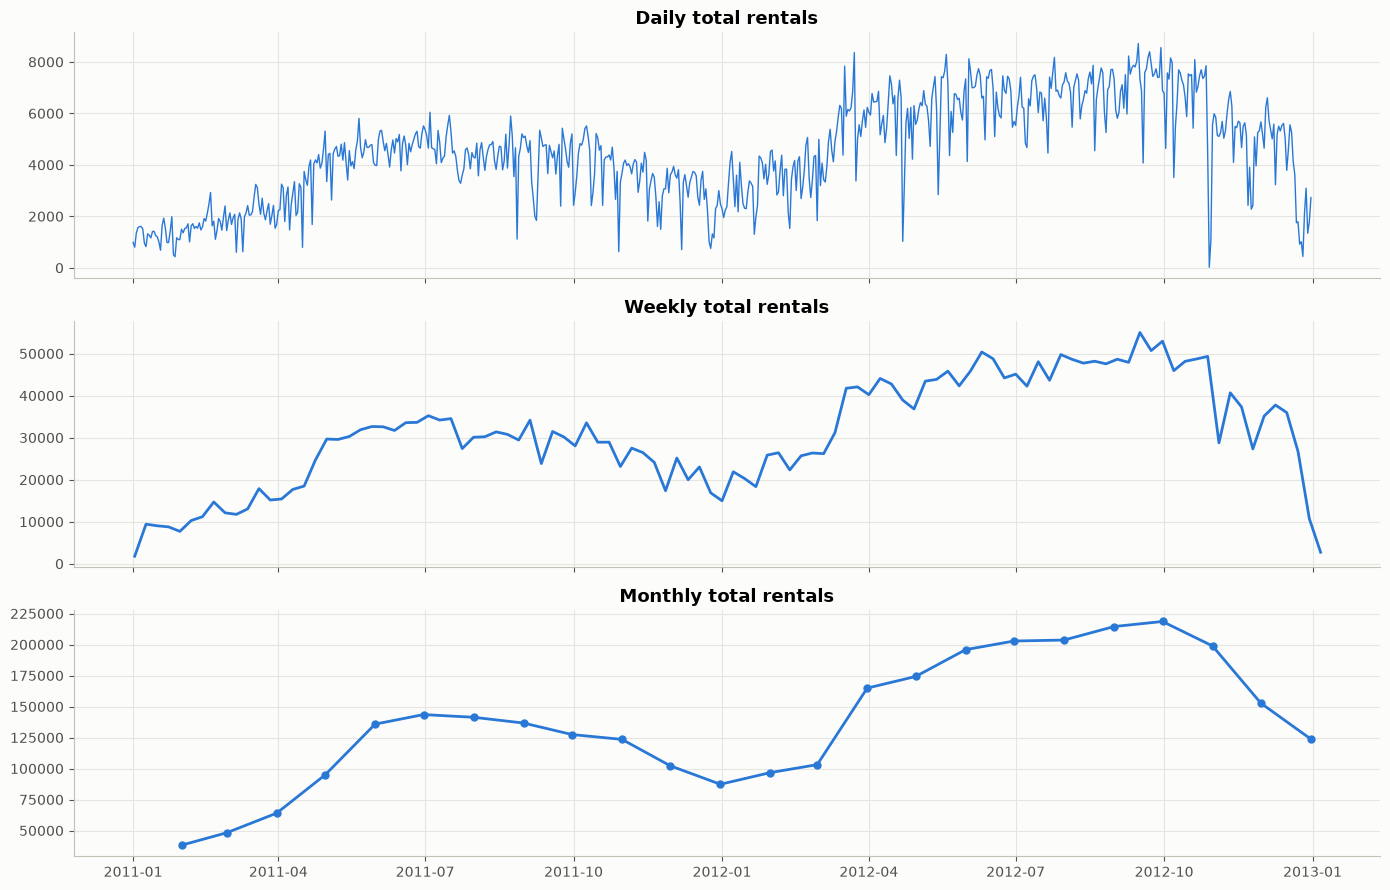

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, (rule, label) in zip(axes, [("D", "Daily"), ("W", "Weekly"), ("ME", "Monthly")]):
    s = hourly["cnt"].resample(rule).sum()
    ax.plot(s, color=PALETTE[0], marker="o" if rule == "ME" else None, markersize=5,
            linewidth=1 if rule == "D" else 2)
    ax.set_title(f"{label} total rentals")
fig.tight_layout()
save_fig(fig, "02_resampling")
plt.show()

In [21]:
# Multiple aggregations at once
hourly.resample("QE").agg({"cnt": "sum", "temp": "mean", "humidity": "mean", "casual": "sum"}).round(1)

,cnt,temp,humidity,casual
datetime,,,,
2011-03-31,150449,11.1,56.8,22141
2011-06-30,374203,23.8,65.9,84008
2011-09-30,405450,28.4,66.6,91839
2011-12-31,313001,16.4,67.7,49264
2012-03-31,364756,14.2,59.0,49308
2012-06-30,572919,24.0,57.8,125985
2012-09-30,636683,28.5,63.3,128680
2012-12-31,475218,15.9,64.3,68792


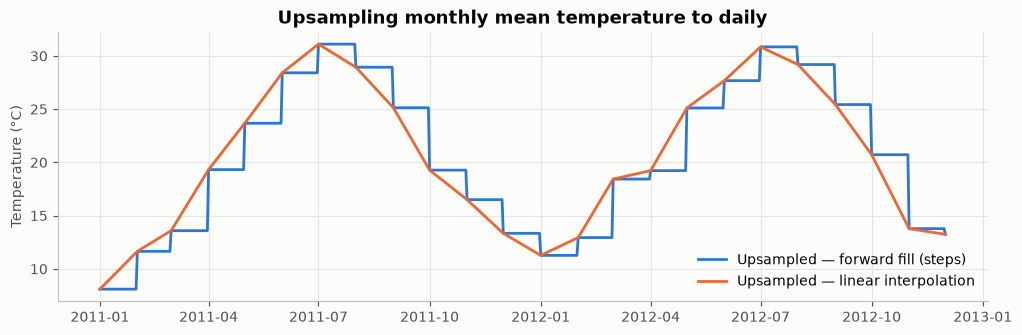

In [22]:
# Upsampling: monthly mean temperature -> daily, filled two ways
monthly_temp = hourly["temp"].resample("MS").mean()
up = pd.DataFrame({"ffill": monthly_temp.resample("D").ffill(),
                   "interpolate": monthly_temp.resample("D").interpolate()})
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(up["ffill"], color=PALETTE[0], label="Upsampled — forward fill (steps)")
ax.plot(up["interpolate"], color=PALETTE[1], label="Upsampled — linear interpolation")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Upsampling monthly mean temperature to daily")
ax.legend()
save_fig(fig, "02_upsampling")
plt.show()

## Summary
- **Univariate:** hourly demand is right-skewed; clear weather dominates.
- **Bivariate:** temperature (+) and humidity (−) are the strongest weather drivers; `temp`/`atemp` are redundant.
- **Multivariate:** hour × day-type interaction is the key structure — commute peaks on weekdays vs a midday hump on weekends.
- **Time series:** strong upward **trend** (~65% growth 2011→2012), **daily, weekly and yearly seasonality**, and irregular shocks such as Hurricane Sandy. The series is non-stationary until differenced.
- **Resampling** to daily/weekly/monthly progressively removes noise and reveals the trend and yearly cycle.